In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

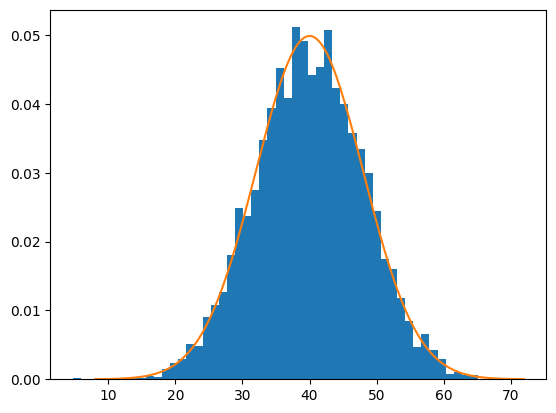

Выборочное среднее: 40.02040214945445
Стандартное отклонение: 8.041853718964987


In [23]:
#Задание 2.1
mu, sigma = 40, 8
sample = np.random.normal(mu, sigma, size=5000)
x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 200)

plt.hist(sample, bins=50, density=True)
plt.plot(x, stats.norm.pdf(x, mu, sigma))
plt.show()

print(f'Выборочное среднее: {sample.mean()}')
print(f'Стандартное отклонение: {sample.std()}')


Выборочное среднее и стандартное отклонение близки к заданным.

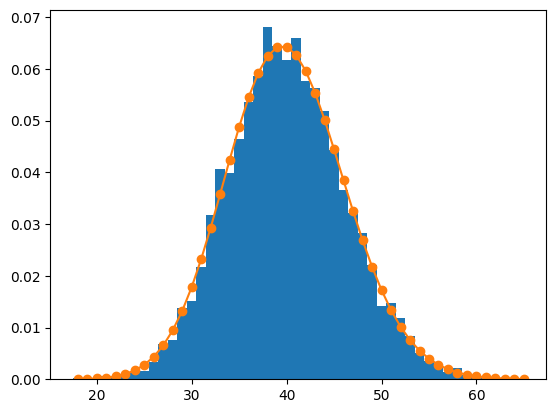

Выборочное среднее: 40.0754
Стандартное отклонение: 6.158807907379479

Теоретическое среднее: 40.0
Теоретическое стандартное отклонение: 6.196773353931867


In [24]:
#Задание 2.2
n, p = 1000, 0.04
sample = np.random.binomial(n, p, size=5000)

k = np.arange(sample.min(), sample.max() + 1)
plt.hist(sample, bins=k-0.5, density = True)
plt.plot(k, stats.binom.pmf(k, n, p), 'o-')
plt.show()

print(f'Выборочное среднее: {sample.mean()}')
print(f'Стандартное отклонение: {sample.std()}\n')
print(f'Теоретическое среднее: {n * p}')
print(f'Теоретическое стандартное отклонение: {np.sqrt(n * p * (1 - p))}')

Выборочное среднее и стандартное отклонение близки к заданным.

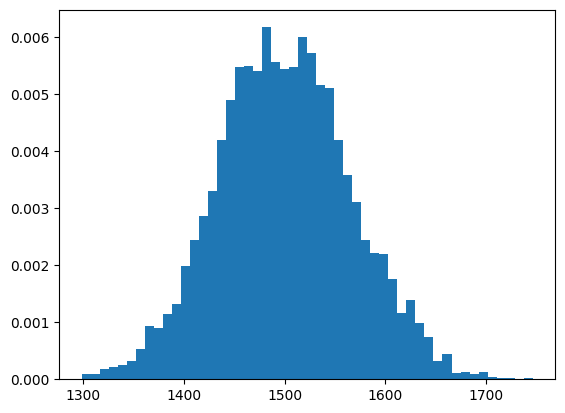

In [30]:
#Задание 2.3
n_per_day = 500
n_days = 5000

daily_means = [
    np.random.exponential(scale=1500, size=n_per_day).mean()
    for _ in range(n_days)
]

plt.hist(daily_means, bins=50, density=True)
plt.show()

Отдельные значения экспоненциального распределения перекошены вправо, то есть много малых значений, а большие значения - редкость. Гистограмма средних по 500 значениям симметрична и похожа нк колокол  вокруг 1500. Это ЦПТ: среднее большой выборки распределено примерно нормально независимо от исходного распределения, а ширина колокола равна σ/(n ** 0.5)

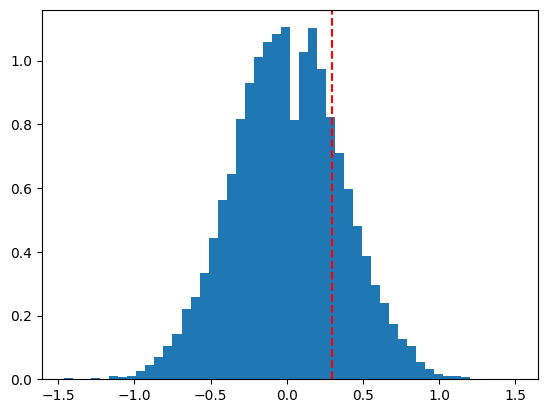

0.1995


In [26]:
#Задание 3.2
n = 5000
p = (155 + 170) / 10000

a = np.random.binomial(n, p, size=10000) / n
b = np.random.binomial(n, p, size=10000) / n
diff = b - a

plt.hist(diff * 100, bins=50, density=True)
plt.axvline(0.3, color='red', linestyle='--')
plt.show()

print((diff >= 0.003).mean())

При отсутствии эффекта кнопки разница >= 0.3 п.п. случайно получается примерно в 21% эксперимента, то есть часто. Значит, рост конверсиис 3,1% до 3,4% это шум, а не эффект новой кнопки.

In [27]:
#Задание 3.3
x = np.array([3, 4, 4, 5, 5, 6, 6, 7, 8, 52])
upper_3s = x.mean() + 3 * x.std(ddof=1)

p25, p75 = np.percentile(x, [25, 75])
upper_pct = p75 + 1.5 * (p75 - p25)
print(upper_3s, upper_pct)

54.49719092257398 10.5


Выброс по правилу трех сигм: отсутствует.

Выброс по перцентилям: 52 > 10.5, поэтому 52 - выброс
Сравнение: лучше сработали перцентили. Значение 52 минуты сильно отличается от остальных, но правило сигм его не нашло, потому что выброс сам учавствует в расчете, увеличивает среднее, и тем самым граница смещается дальше самого выброса. Перцентили зависят от порядка значений, а не от их величины, поэтому устойчивы к выбросам